In [1]:
import os
import json
import google.generativeai as genai

from dotenv import load_dotenv
from PIL import Image

C:\Anaconda3\envs\genai\lib\site-packages\google\api_core\_python_version_support.py:273: FutureWarning: You are using a Python version (3.10.20) which Google will stop supporting in new releases of google.api_core once it reaches its end of life (2026-10-04). Please upgrade to the latest Python version, or at least Python 3.11, to continue receiving updates for google.api_core past that date.
  warnings.warn(message, FutureWarning)
C:\Anaconda3\envs\genai\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
load_dotenv()

api_key = os.getenv("GOOGLE_API_KEY")

genai.configure(api_key=api_key)

In [3]:
model = genai.GenerativeModel("gemini-2.5-flash")

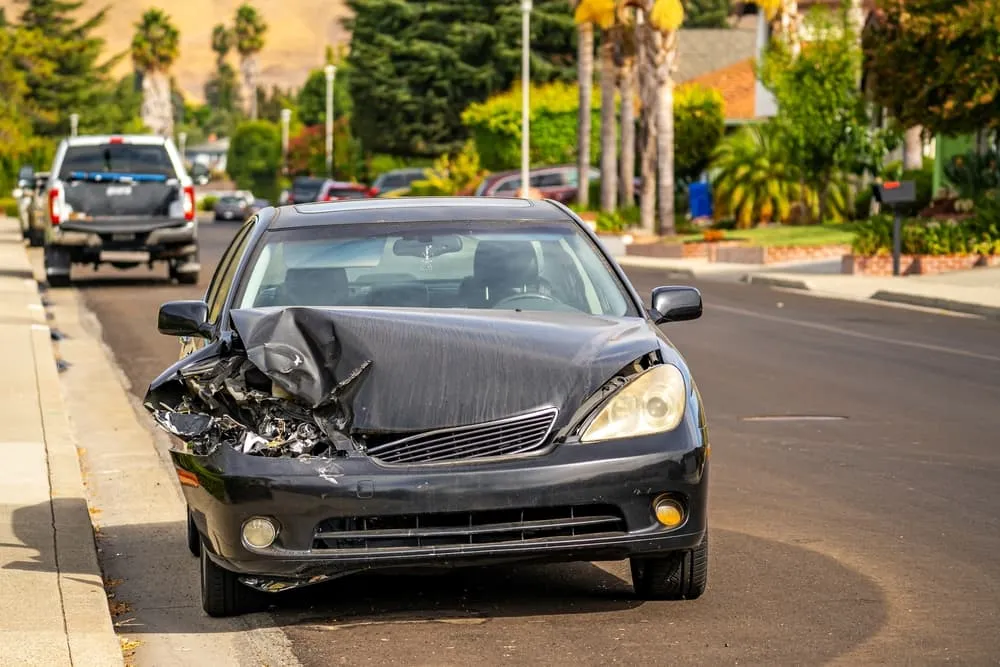

In [4]:
image = Image.open("../data/accident_images/accident1.jpg")

image

In [5]:
prompt = """
You are an automobile insurance damage assessor.

Analyze the accident image.

Return ONLY valid JSON.

Do NOT use markdown.

Do NOT use ```json.

Return ONLY the JSON object.

Format:

{
  "damaged_parts": [],
  "severity": "",
  "damage_summary": ""
}
"""

In [6]:
response = model.generate_content(
    [prompt, image]
)

print(response.text)

{
  "damaged_parts": [
    "Hood",
    "Front Bumper",
    "Driver's Side Front Fender",
    "Driver's Side Headlight Assembly",
    "Grille",
    "Radiator Support (likely)",
    "Radiator (likely)"
  ],
  "severity": "Severe",
  "damage_summary": "The black sedan sustained severe frontal impact damage, primarily concentrated on the driver's side. The hood is extensively crumpled and deformed. The front bumper is crushed and fractured on the driver's side. The driver's side front fender and headlight assembly are completely destroyed and missing, exposing internal engine bay components. The front grille is severely damaged and deformed. The extent of the damage indicates significant structural compromise to the vehicle's front end, likely affecting the radiator support and other critical components."
}


In [7]:
import json

result = json.loads(response.text)

print(result)

{'damaged_parts': ['Hood', 'Front Bumper', "Driver's Side Front Fender", "Driver's Side Headlight Assembly", 'Grille', 'Radiator Support (likely)', 'Radiator (likely)'], 'severity': 'Severe', 'damage_summary': "The black sedan sustained severe frontal impact damage, primarily concentrated on the driver's side. The hood is extensively crumpled and deformed. The front bumper is crushed and fractured on the driver's side. The driver's side front fender and headlight assembly are completely destroyed and missing, exposing internal engine bay components. The front grille is severely damaged and deformed. The extent of the damage indicates significant structural compromise to the vehicle's front end, likely affecting the radiator support and other critical components."}


In [8]:
print(result["damaged_parts"])
print(result["severity"])
print(result["damage_summary"])

['Hood', 'Front Bumper', "Driver's Side Front Fender", "Driver's Side Headlight Assembly", 'Grille', 'Radiator Support (likely)', 'Radiator (likely)']
Severe
The black sedan sustained severe frontal impact damage, primarily concentrated on the driver's side. The hood is extensively crumpled and deformed. The front bumper is crushed and fractured on the driver's side. The driver's side front fender and headlight assembly are completely destroyed and missing, exposing internal engine bay components. The front grille is severely damaged and deformed. The extent of the damage indicates significant structural compromise to the vehicle's front end, likely affecting the radiator support and other critical components.


In [9]:
import pandas as pd

repair_cost = {
    "Part": [
        "Front Bumper",
        "Rear Bumper",
        "Hood",
        "Front Grille",
        "Radiator",
        "Left Headlight",
        "Right Headlight",
        "Left Fog Light",
        "Right Fog Light",
        "Windshield",
        "Front Windshield Wiper",
        "Rear Windshield",
        "Roof",
        "Left Fender",
        "Right Fender",
        "Left Front Door",
        "Right Front Door",
        "Left Rear Door",
        "Right Rear Door",
        "Left Side Mirror",
        "Right Side Mirror",
        "Left Front Wheel",
        "Right Front Wheel",
        "Left Rear Wheel",
        "Right Rear Wheel",
        "Left Front Tire",
        "Right Front Tire",
        "Left Rear Tire",
        "Right Rear Tire",
        "Front Suspension",
        "Rear Suspension",
        "Engine",
        "Battery",
        "Trunk",
        "Tailgate",
        "Left Tail Light",
        "Right Tail Light",
        "Exhaust",
        "Number Plate"
    ],
    "Cost": [
        7500, 7000, 12000, 4500, 10000,
        5200, 5200, 1800, 1800, 8000,
        1200, 7000, 20000, 6000, 6000,
        15000, 15000, 14000, 14000, 3000,
        3000, 9000, 9000, 9000, 9000,
        5000, 5000, 5000, 5000, 18000,
        16000, 150000, 12000, 18000, 20000,
        3500, 3500, 10000, 800
    ]
}

df = pd.DataFrame(repair_cost)

df.to_csv("../database/repair_cost.csv", index=False)

print("CSV created successfully!")

df.head()

CSV created successfully!


,Part,Cost
0,Front Bumper,7500
1,Rear Bumper,7000
2,Hood,12000
3,Front Grille,4500
4,Radiator,10000
